# Step 3 — Exploratory Data Analysis (EDA)

**Mục tiêu:**
- Thống kê mô tả
- Trực quan hóa phân phối các biến
- Khám phá mối quan hệ giữa các biến với nhau và với biến mục tiêu `deposit`
- Rút ra các insights có ý nghĩa kinh doanh

> **Lưu ý:** dữ liệu đầu vào là `bank_data_cleaned.csv` đã được làm sạch ở mức từng dòng. File này **chưa cắt ngoại lai** và **còn nhãn `unknown`**, nên phân phối `balance`, `duration`, `campaign` có đuôi rất dài (các biểu đồ histogram được cắt ở phân vị 99% để dễ nhìn).
> Tỉ lệ khách đồng ý trung bình chỉ **11.7%** — đây là mốc tham chiếu cho mọi biểu đồ tỉ lệ bên dưới.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

df = pd.read_csv('bank_data_cleaned.csv')
df['deposit_label'] = df['y'].map({1: 'Yes', 0: 'No'})
BASE = df['y'].mean() * 100          # tỉ lệ Yes toàn tập (mốc tham chiếu)

print(f'Shape: {df.shape} | Tỉ lệ Yes toàn tập: {BASE:.1f}%')
df.head()

Shape: (45208, 18) | Tỉ lệ Yes toàn tập: 11.7%


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,deposit_label
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,nonexistent,0,No
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,nonexistent,0,No
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,nonexistent,0,No
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,nonexistent,0,No
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,nonexistent,0,No


---
## 3.1 Thống kê mô tả (Descriptive Statistics)

In [ ]:
print('--- Biến định lượng ---')
display(df.describe().round(2))

--- Biến định lượng ---


,age,balance,day,duration,campaign,pdays,previous,y
count,45208.00,45208.00,45208.00,45208.00,45208.00,45208.00,45208.00,45208.00
mean,40.94,1362.23,15.81,258.18,2.76,40.20,0.58,0.12
std,10.62,3044.79,8.32,257.53,3.10,100.13,2.30,0.32
min,18.00,-8019.00,1.00,1.00,1.00,-1.00,0.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00,1.00


In [ ]:
print('--- Biến định tính ---')
display(df.describe(include=['object']).T)
print('\nSố nhãn "unknown" ở mỗi cột:')
print({c: int((df[c] == 'unknown').sum()) for c in ['job', 'education', 'contact', 'poutcome']})

--- Biến định tính ---


,count,unique,top,freq
job,45208,12,blue-collar,9732
marital,45208,3,married,27211
education,45208,4,secondary,23200
default,45208,2,no,44393
housing,45208,2,yes,25128
loan,45208,2,no,37965
contact,45208,3,cellular,29283
month,45208,12,may,13764
poutcome,45208,5,nonexistent,36951
deposit_label,45208,2,No,39919



Số nhãn "unknown" ở mỗi cột:
{'job': 288, 'education': 1857, 'contact': 13019, 'poutcome': 5}


In [ ]:
print('--- Kiểm tra missing values ---')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'Không có missing values')

--- Kiểm tra missing values ---
Không có missing values ✅


---
## 3.2 Phân phối biến mục tiêu — `deposit`

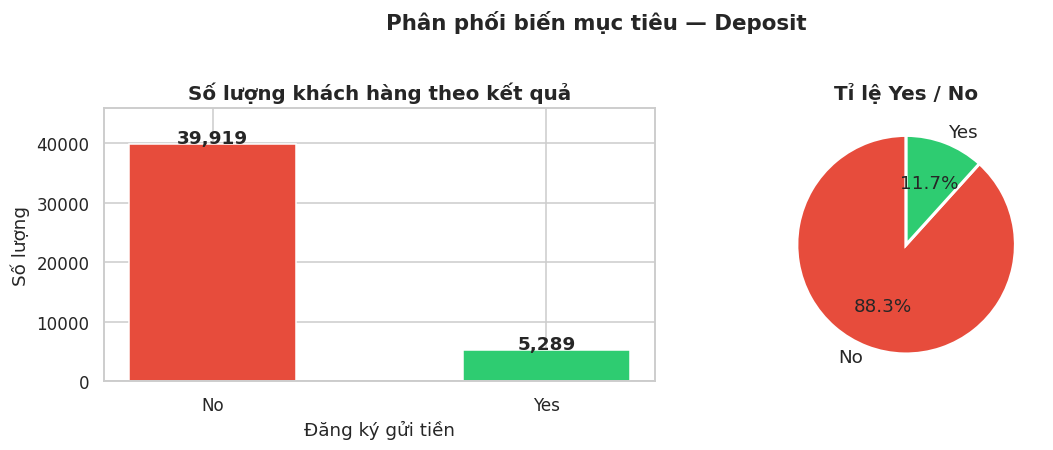

Yes (gửi tiền) : 5,289 (11.7%)
No  (không gửi): 39,919 (88.3%)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# --- Countplot ---
counts = df['deposit_label'].value_counts()
colors = ['#e74c3c', '#2ecc71']
ax = axes[0]
bars = ax.bar(counts.index, counts.values, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 60,
            f'{val:,}', ha='center', fontsize=12, fontweight='bold')
ax.set_title('Số lượng khách hàng theo kết quả', fontsize=13, fontweight='bold')
ax.set_xlabel('Đăng ký gửi tiền')
ax.set_ylabel('Số lượng')
ax.set_ylim(0, max(counts.values) * 1.15)

# --- Pie chart ---
ax2 = axes[1]
ax2.pie(counts.values, labels=counts.index, autopct='%1.1f%%',
        colors=colors, startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2},
        textprops={'fontsize': 12})
ax2.set_title('Tỉ lệ Yes / No', fontsize=13, fontweight='bold')

plt.suptitle('Phân phối biến mục tiêu — Deposit', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'Yes (gửi tiền) : {counts["Yes"]:,} ({counts["Yes"]/len(df)*100:.1f}%)')
print(f'No  (không gửi): {counts["No"]:,} ({counts["No"]/len(df)*100:.1f}%)')


---
## 3.3 Phân phối các biến số liên tục

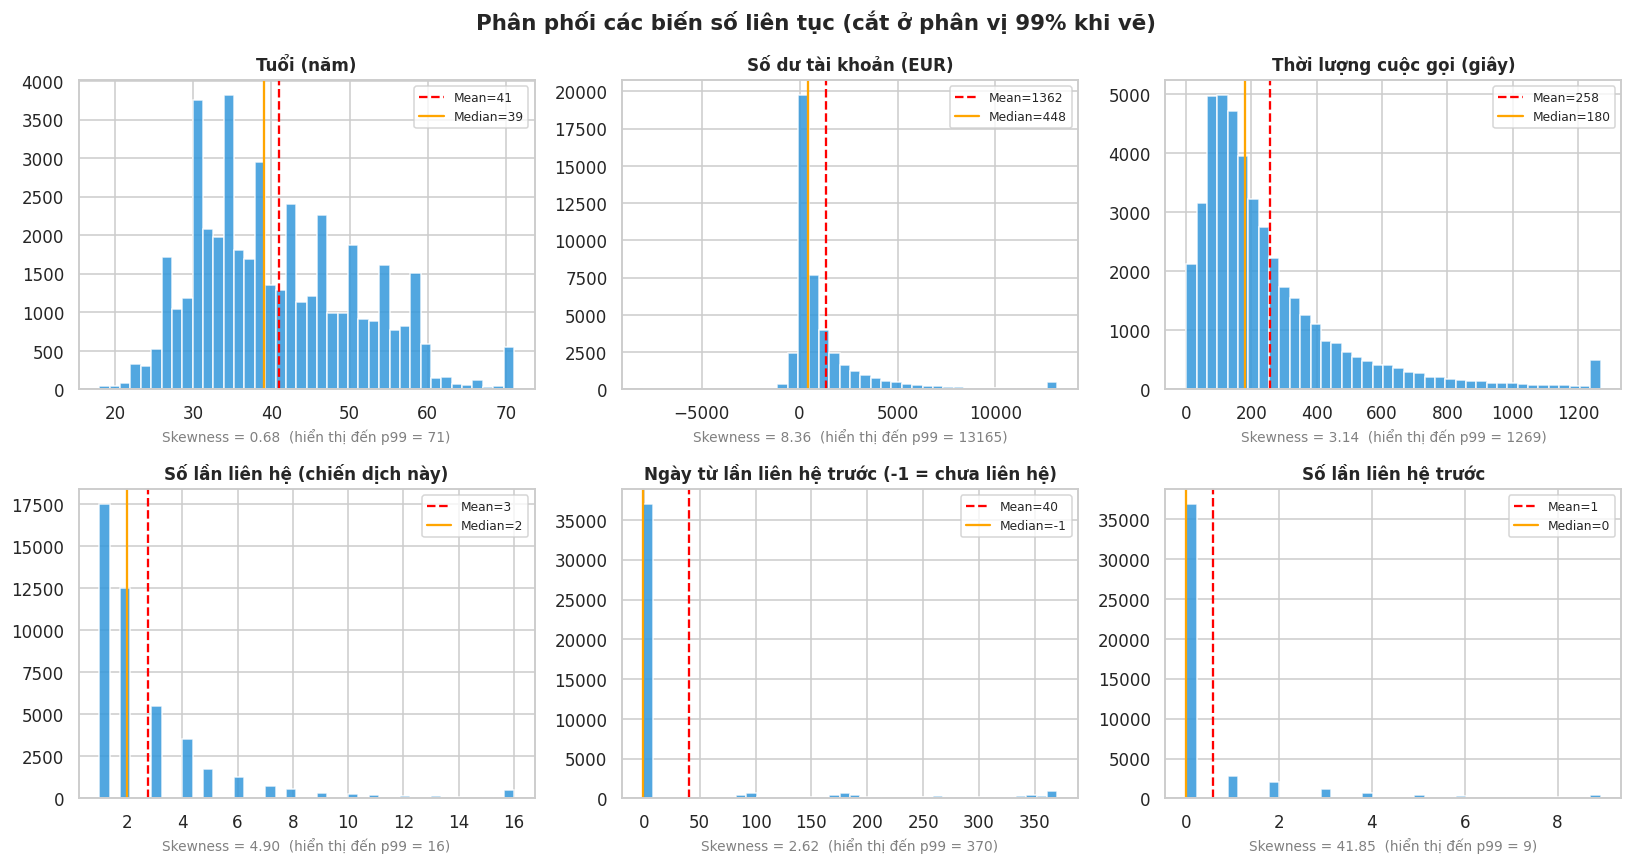

In [ ]:
num_cols = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']
col_labels = {
    'age'     : 'Tuổi (năm)',
    'balance' : 'Số dư tài khoản (EUR)',
    'duration': 'Thời lượng cuộc gọi (giây)',
    'campaign': 'Số lần liên hệ (chiến dịch này)',
    'pdays'   : 'Ngày từ lần liên hệ trước (-1 = chưa liên hệ)',
    'previous': 'Số lần liên hệ trước'
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    cap = df[col].quantile(0.99)
    ax.hist(df[col].clip(upper=cap), bins=40, color='#3498db', edgecolor='white', alpha=0.85)   # chỉ để vẽ, không đổi dữ liệu
    ax.axvline(df[col].mean(),   color='red',    linestyle='--', linewidth=1.5, label=f'Mean={df[col].mean():.0f}')
    ax.axvline(df[col].median(), color='orange', linestyle='-',  linewidth=1.5, label=f'Median={df[col].median():.0f}')
    ax.set_title(col_labels[col], fontsize=11, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_xlabel(f'Skewness = {df[col].skew():.2f}  (hiển thị đến p99 = {cap:.0f})', fontsize=9, color='gray')

plt.suptitle('Phân phối các biến số liên tục (cắt ở phân vị 99% khi vẽ)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Nhận xét phân phối các biến số liên tục

- **age**: lệch phải nhẹ *(skew = 0.68)*, tập trung ở nhóm **30–50 tuổi**. Mean = **41**, median = **39**, đuôi kéo đến **95 tuổi**.
- **balance**: lệch phải cực mạnh *(skew = 8.36)*: median chỉ **448 EUR** nhưng mean = **1,362 EUR**, giá trị lớn nhất tới **102,127 EUR**, và có cả số dư âm (đến −8,019). Vài khách giàu kéo mean lên rất nhiều.
- **duration**: lệch phải mạnh *(skew = 3.14)*. Median = **180 giây**, mean = **258 giây**, cuộc gọi dài nhất **4,918 giây**.
- **campaign**: lệch phải mạnh *(skew = 4.90)*. Đa số khách được liên hệ **1–3 lần** (median = 2), nhưng có người bị gọi tới **63 lần**.
- **pdays**: median = **−1** vì phần lớn khách **chưa từng được liên hệ** ở chiến dịch trước; phần còn lại phân tán đến **871 ngày**.
- **previous**: gần như toàn bộ bằng **0** *(skew = 41.85)*, một vài khách có tới **275** lần liên hệ trước (rất có thể là dữ liệu nhập bất thường).

→ Vì đuôi dài như vậy, bước mô hình có **cắt ngoại lai (IQR) bên trong Pipeline** và chuẩn hóa thang đo.

---
## 3.4 So sánh biến số theo Deposit (Boxplot)

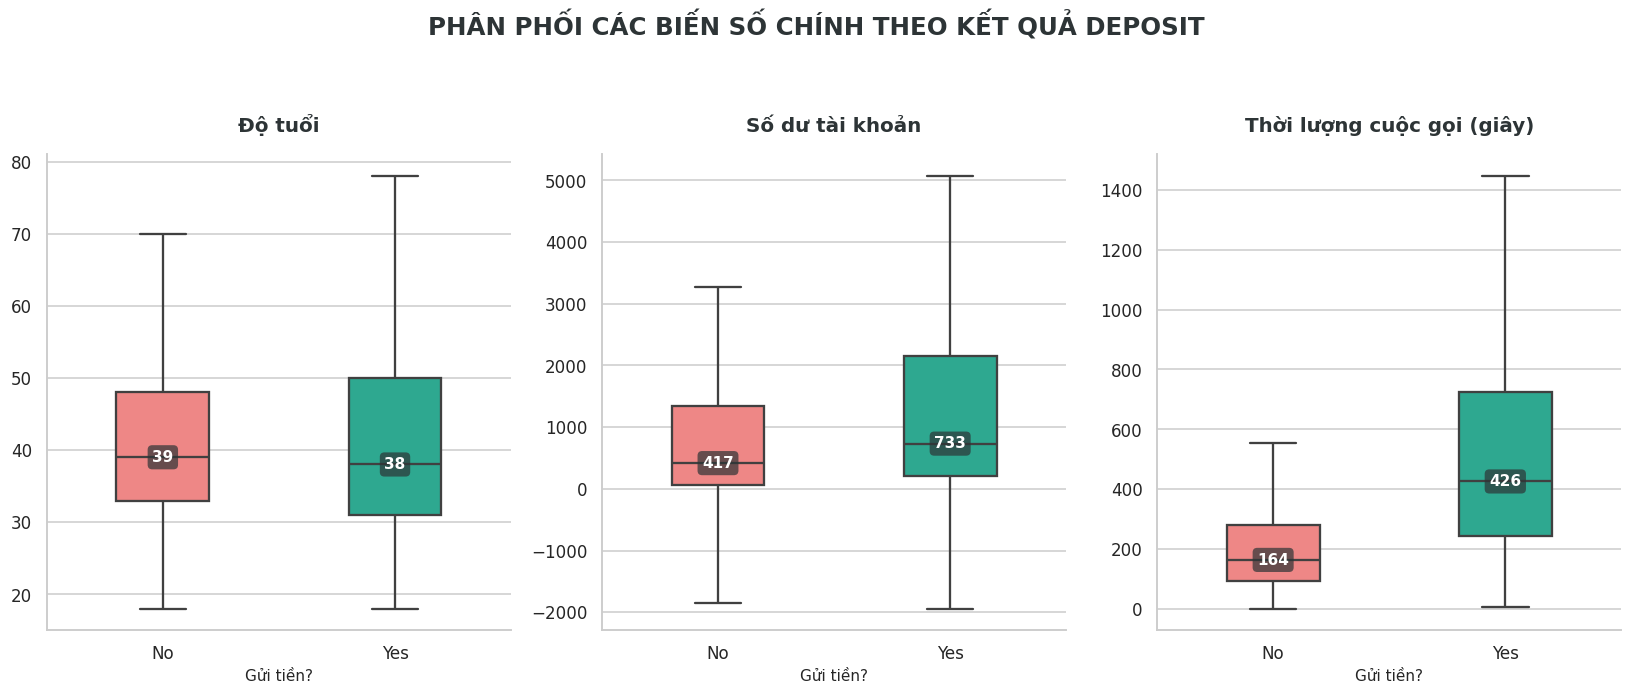

----------------------------------------
Biến số         | Median Yes | Median No 
----------------------------------------
age             | 38         | 39        
balance         | 733        | 417       
duration        | 426        | 164       


In [ ]:
sns.set_theme(style="whitegrid") # Tạo lưới mờ sang trọng
palette = {'Yes': '#1abc9c', 'No': '#ff7675'} 

fig, axes = plt.subplots(1, 3, figsize=(15, 6))

if 'deposit_label' not in df.columns:
    df['deposit_label'] = df['y'].map({1: 'Yes', 0: 'No'})

columns = ['age', 'balance', 'duration']
labels = ['Độ tuổi', 'Số dư tài khoản', 'Thời lượng cuộc gọi (giây)']

for ax, col, label in zip(axes, columns, labels):
    sns.boxplot(data=df, x='deposit_label', y=col, hue='deposit_label',
                palette=palette, ax=ax, width=0.4, linewidth=1.5, 
                showfliers=False, legend=False) 
    
    ax.set_title(label, fontsize=13, fontweight='bold', pad=15, color='#2d3436')
    ax.set_xlabel('Gửi tiền?', fontsize=10)
    ax.set_ylabel('')
    
    sns.despine(ax=ax)

    for i, grp in enumerate(['No', 'Yes']):
        med = df[df['deposit_label'] == grp][col].median()
        
        ax.text(i, med, f'{med:.0f}', 
                ha='center', va='center', 
                fontsize=10, fontweight='bold', 
                color='white',
                # Thêm khung đen mờ (bbox) để số nổi bật trên nền biểu đồ
                bbox=dict(facecolor='#2d3436', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.3'))

plt.suptitle('PHÂN PHỐI CÁC BIẾN SỐ CHÍNH THEO KẾT QUẢ DEPOSIT', 
             fontsize=16, fontweight='bold', y=1.05, color='#2d3436')

plt.tight_layout()
plt.show()

print("-" * 40)
print(f"{'Biến số':<15} | {'Median Yes':<10} | {'Median No':<10}")
print("-" * 40)
for col in columns:
    m_yes = df[df['y'] == 1][col].median()
    m_no  = df[df['y'] == 0][col].median()
    print(f"{col:<15} | {m_yes:<10.0f} | {m_no:<10.0f}")

---
## 3.5 Tỉ lệ gửi tiền theo các biến phân loại

### 3.5.1 Theo nghề nghiệp (`job`)



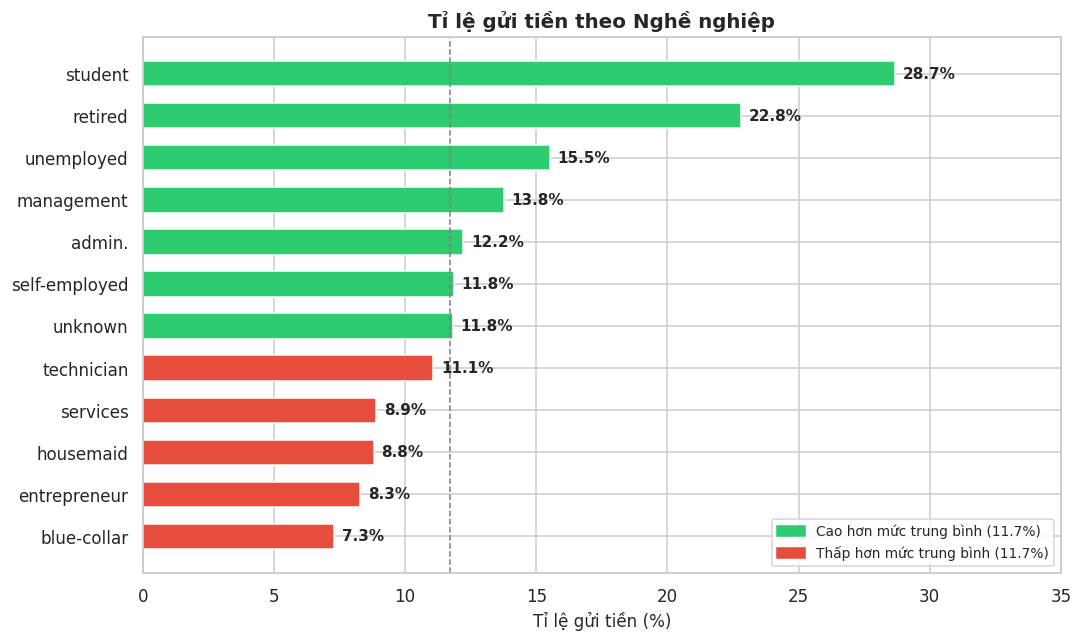

In [ ]:
job_rate = df.groupby('job')['y'].mean().sort_values(ascending=True) * 100

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#e74c3c' if v < BASE else '#2ecc71' for v in job_rate.values]
bars = ax.barh(job_rate.index, job_rate.values, color=colors, edgecolor='white', height=0.6)
for bar, val in zip(bars, job_rate.values):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontsize=10, fontweight='bold')

ax.axvline(BASE, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('Tỉ lệ gửi tiền (%)', fontsize=11)
ax.set_title('Tỉ lệ gửi tiền theo Nghề nghiệp', fontsize=13, fontweight='bold')
ax.set_xlim(0, 35)
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color='#2ecc71', label=f'Cao hơn mức trung bình ({BASE:.1f}%)'),
    Patch(color='#e74c3c', label=f'Thấp hơn mức trung bình ({BASE:.1f}%)'),
], fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

**Nhận xét nghề nghiệp:** `student` (**28.7%**) và `retired` (**22.8%**) cao gấp 2–2.5 lần mức trung bình; `blue-collar` thấp nhất (**7.3%**), tiếp đến `entrepreneur` (8.3%), `housemaid` (8.8%), `services` (8.9%).

### 3.5.2 Theo trình độ học vấn (`education`)

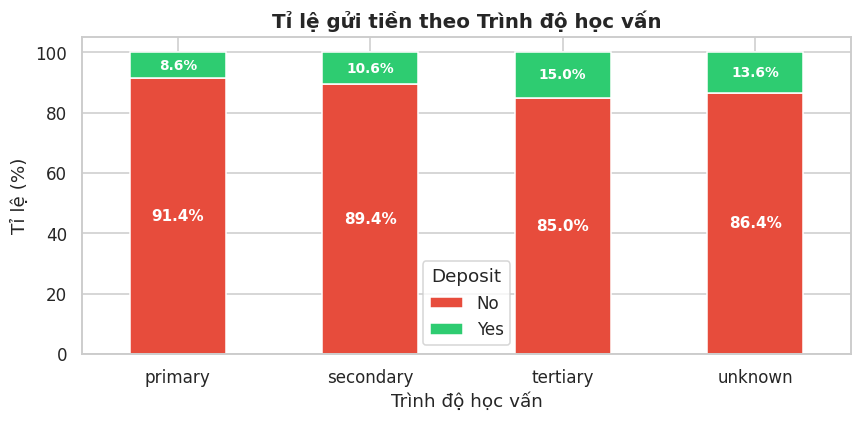

In [ ]:
edu_order = ['primary', 'secondary', 'tertiary', 'unknown']
ct_edu = pd.crosstab(df['education'], df['deposit_label'], normalize='index') * 100
ct_edu = ct_edu.reindex([e for e in edu_order if e in ct_edu.index])

fig, ax = plt.subplots(figsize=(8, 4))
ct_edu.plot(kind='bar', stacked=True, ax=ax,
            color=['#e74c3c', '#2ecc71'], edgecolor='white', width=0.5)

for i, (idx, row) in enumerate(ct_edu.iterrows()):
    ax.text(i, row['No']/2, f"{row['No']:.1f}%", ha='center', va='center',
            color='white', fontweight='bold', fontsize=10)
    ax.text(i, row['No'] + row['Yes']/2, f"{row['Yes']:.1f}%", ha='center', va='center',
            color='white', fontweight='bold', fontsize=9)

ax.set_title('Tỉ lệ gửi tiền theo Trình độ học vấn', fontsize=13, fontweight='bold')
ax.set_xlabel('Trình độ học vấn')
ax.set_ylabel('Tỉ lệ (%)')
ax.set_xticklabels(ct_edu.index, rotation=0)
ax.legend(title='Deposit', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()

**Nhận xét học vấn:** tỉ lệ đồng ý tăng theo học vấn: `primary` **8.6%** → `secondary` **10.6%** → `tertiary` **15.0%**.

### 3.5.3 Theo kết quả chiến dịch trước (`poutcome`)

> **Insight:** khách từng tham gia thành công ở chiến dịch trước (`success`) có tỉ lệ gửi tiền lần này lên tới **64.7%** — cao nhất trong các nhóm phân loại (gấp ~5.5 lần mức trung bình 11.7%). Tuy nhiên nhóm này nhỏ (**1,511 khách ≈ 3.3%** tổng số). Nhóm `nonexistent` (chưa từng liên hệ) chỉ đạt **9.2%**.

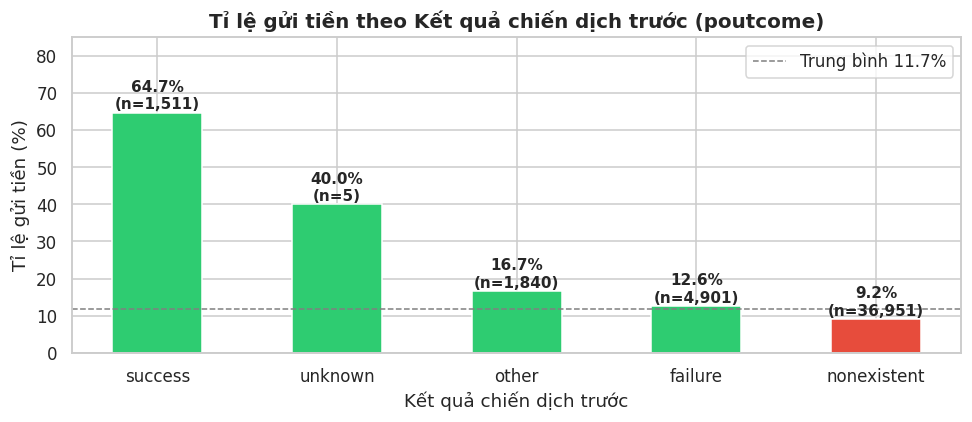

In [ ]:
pout_rate = df.groupby('poutcome')['y'].mean().sort_values(ascending=False) * 100
pout_cnt  = df['poutcome'].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#2ecc71' if v >= BASE else '#e74c3c' for v in pout_rate.values]
bars = ax.bar(pout_rate.index, pout_rate.values, color=colors, edgecolor='white', width=0.5)
for bar, (name, val) in zip(bars, pout_rate.items()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.1f}%\n(n={pout_cnt[name]:,})', ha='center', fontsize=10, fontweight='bold')

ax.axhline(BASE, color='gray', linestyle='--', linewidth=1, label=f'Trung bình {BASE:.1f}%')
ax.set_title('Tỉ lệ gửi tiền theo Kết quả chiến dịch trước (poutcome)', fontsize=13, fontweight='bold')
ax.set_xlabel('Kết quả chiến dịch trước')
ax.set_ylabel('Tỉ lệ gửi tiền (%)')
ax.set_ylim(0, 85)
ax.legend()
plt.tight_layout()
plt.show()

### 3.5.4 Theo tháng (`month`)


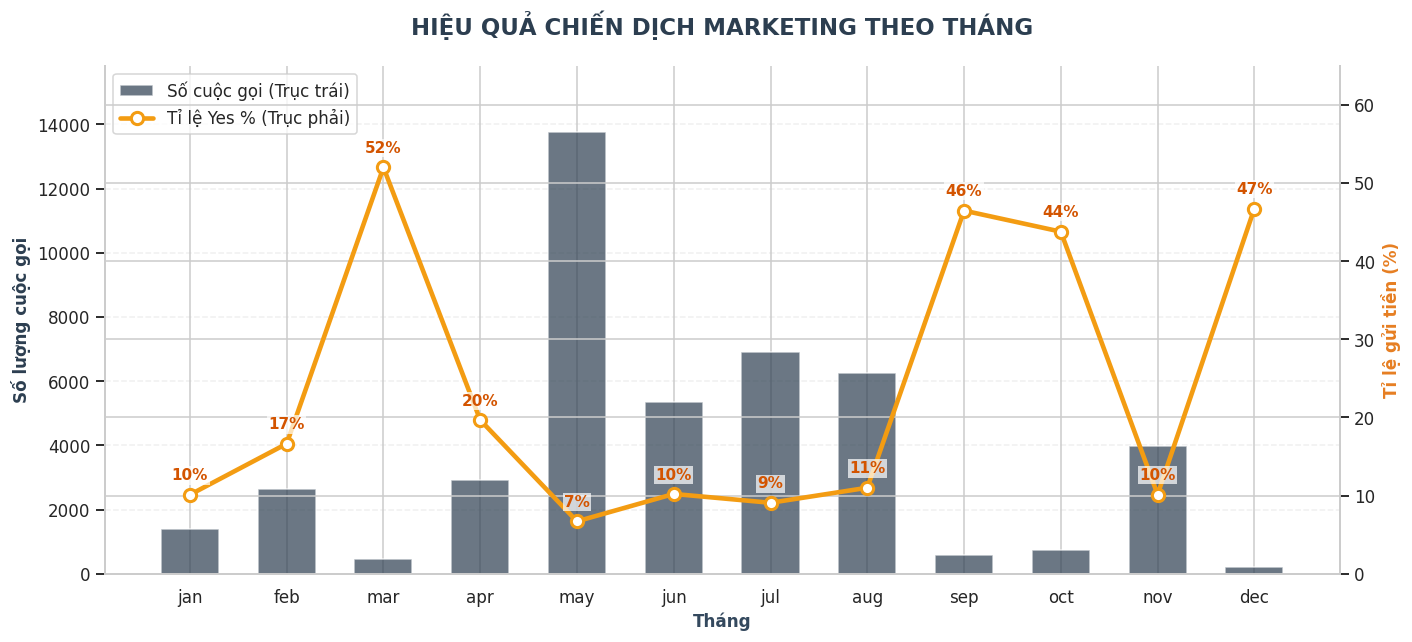

In [ ]:
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun',
               'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_order = [m for m in month_order if m in df['month'].unique()]

month_rate  = df.groupby('month')['y'].mean().reindex(month_order) * 100
month_count = df.groupby('month')['y'].count().reindex(month_order)

fig, ax1 = plt.subplots(figsize=(13, 6))
ax2 = ax1.twinx()

bars = ax1.bar(month_order, month_count.values, color='#2c3e50', alpha=0.7,
               width=0.6, label='Số cuộc gọi (Trục trái)')

line = ax2.plot(month_order, month_rate.values, color='#f39c12', marker='o',
                linewidth=3, markersize=8, markerfacecolor='white', 
                markeredgewidth=2, label='Tỉ lệ Yes % (Trục phải)')

for i, r in enumerate(month_rate.values):
    ax2.text(i, r + 1.5, f'{r:.0f}%', ha='center', va='bottom',
             fontsize=10, color='#d35400', fontweight='bold',
             bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=1))

ax1.set_xlabel('Tháng', fontsize=11, fontweight='bold', color='#34495e')
ax1.set_ylabel('Số lượng cuộc gọi', fontsize=11, color='#2c3e50', fontweight='bold')
ax2.set_ylabel('Tỉ lệ gửi tiền (%)', fontsize=11, color='#e67e22', fontweight='bold')

ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.grid(axis='y', linestyle='--', alpha=0.3) # Chỉ để lưới ngang cho trục chính

ax1.set_ylim(0, month_count.max() * 1.15)
ax2.set_ylim(0, 65)

ax1.set_title('HIỆU QUẢ CHIẾN DỊCH MARKETING THEO THÁNG',
              fontsize=15, fontweight='bold', pad=20, color='#2c3e50')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

## Nhận xét theo tháng

| Tháng | Số cuộc gọi | Tỉ lệ Yes |
|---|---|---|
| **May** | **13,764** (nhiều nhất) | **6.7%** (thấp nhất) |
| Jul / Jun / Nov / Aug | 3,970 – 6,895 | 9–11% |
| **Mar** | 477 | **52.0%** |
| **Dec** | 214 | 46.7% |
| **Sep** | 579 | 46.5% |
| **Oct** | 738 | 43.8% |

- **Tháng 5** chiếm gần **30%** tổng số cuộc gọi nhưng chuyển đổi kém nhất.
- Các tháng **Mar, Sep, Oct, Dec** có tỉ lệ rất cao (44–52%) nhưng **số cuộc gọi ít** (214–738). Có thể ngân hàng chỉ gọi chọn lọc vào các tháng này, nên **chưa thể kết luận** "cứ gọi nhiều hơn vào các tháng này sẽ giữ được tỉ lệ đó".

### 3.5.5 Theo vay thế chấp và vay cá nhân (`housing` & `loan`)


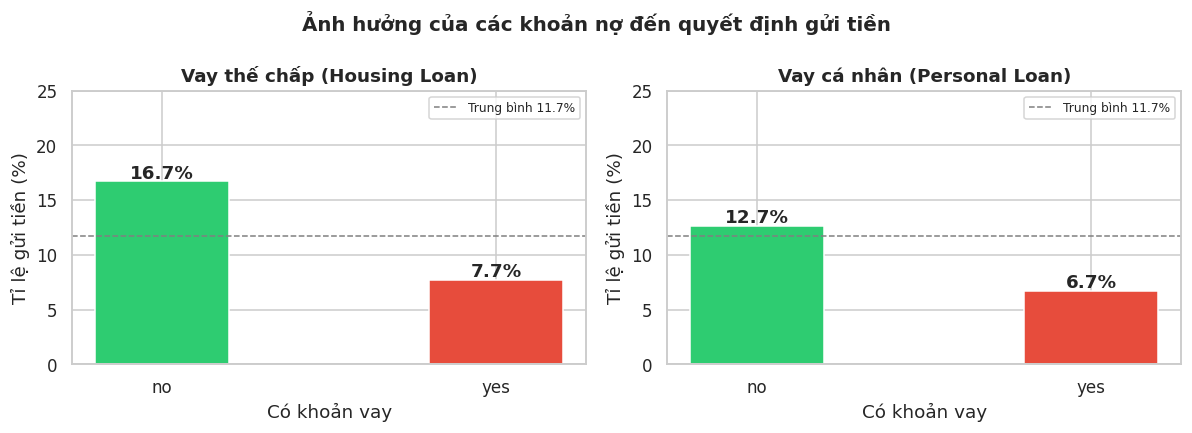

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, col, title in zip(axes,
                           ['housing', 'loan'],
                           ['Vay thế chấp (Housing Loan)', 'Vay cá nhân (Personal Loan)']):
    rate = df.groupby(col)['y'].mean() * 100
    colors = ['#e74c3c' if v < BASE else '#2ecc71' for v in rate.values]
    bars = ax.bar(rate.index, rate.values, color=colors, edgecolor='white', width=0.4)
    for bar, val in zip(bars, rate.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                f'{val:.1f}%', ha='center', fontsize=12, fontweight='bold')
    ax.axhline(BASE, color='gray', linestyle='--', linewidth=1, label=f'Trung bình {BASE:.1f}%')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Có khoản vay')
    ax.set_ylabel('Tỉ lệ gửi tiền (%)')
    ax.set_ylim(0, 25)
    ax.legend(fontsize=8)

plt.suptitle('Ảnh hưởng của các khoản nợ đến quyết định gửi tiền', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Nhận xét:** khách **có vay thế chấp** chỉ đồng ý **7.7%** so với **16.7%** ở khách không vay; khách **có vay cá nhân** đồng ý **6.7%** so với **12.7%**. Khoản nợ làm giảm xác suất gửi tiền rõ rệt.

---
## 3.6 Phân tích theo nhóm tuổi

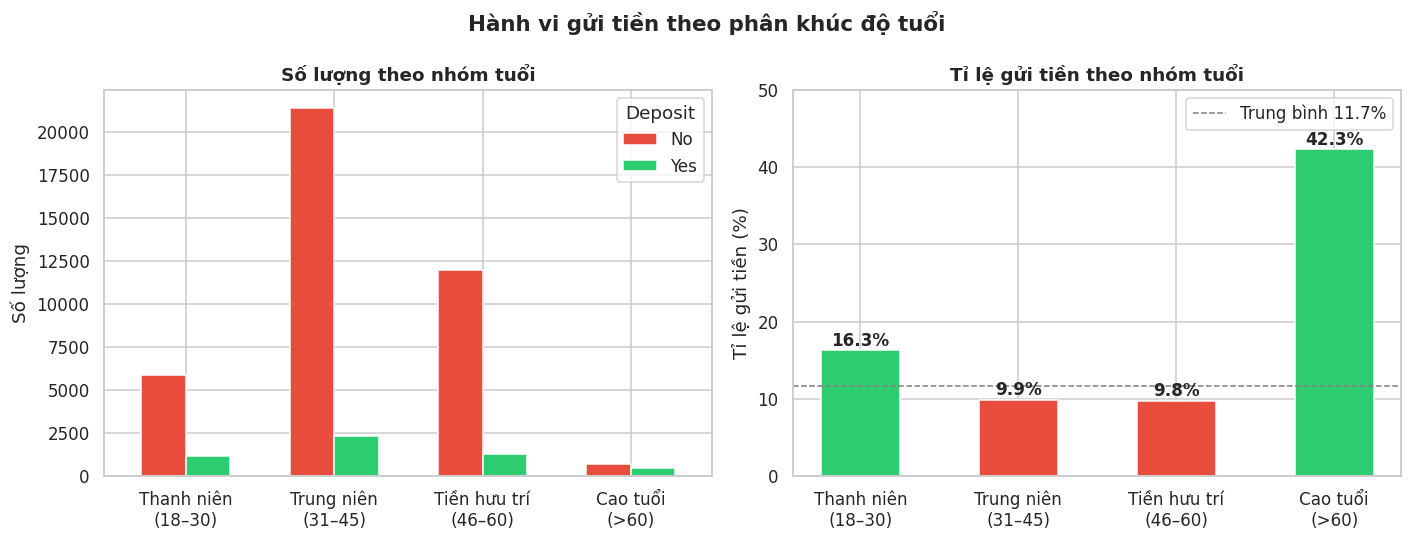

In [ ]:
bins   = [17, 30, 45, 60, 100]
labels = ['Thanh niên\n(18–30)', 'Trung niên\n(31–45)', 'Tiền hưu trí\n(46–60)', 'Cao tuổi\n(>60)']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ct = pd.crosstab(df['age_group'], df['deposit_label'])
ct[['No', 'Yes']].plot(kind='bar', ax=ax, color=['#e74c3c', '#2ecc71'], edgecolor='white', width=0.6)
ax.set_title('Số lượng theo nhóm tuổi', fontsize=12, fontweight='bold')
ax.set_xlabel('')
ax.set_ylabel('Số lượng')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title='Deposit')

ax2 = axes[1]
rate_age = df.groupby('age_group', observed=True)['y'].mean() * 100
colors = ['#2ecc71' if v >= BASE else '#e74c3c' for v in rate_age.values]
bars = ax2.bar(rate_age.index, rate_age.values, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, rate_age.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.6, f'{val:.1f}%', ha='center', fontsize=11, fontweight='bold')
ax2.axhline(BASE, color='gray', linestyle='--', linewidth=1, label=f'Trung bình {BASE:.1f}%')
ax2.set_title('Tỉ lệ gửi tiền theo nhóm tuổi', fontsize=12, fontweight='bold')
ax2.set_xlabel('')
ax2.set_ylabel('Tỉ lệ gửi tiền (%)')
ax2.set_ylim(0, 50)
ax2.legend()

plt.suptitle('Hành vi gửi tiền theo phân khúc độ tuổi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Nhận xét

- **Nhóm thanh niên (18–30)**: tỉ lệ **16.3%** (7,030 khách) — cao hơn mức trung bình.
- **Nhóm trung niên (31–45)**: đông nhất (**23,731 khách**) nhưng tỉ lệ chỉ **9.9%** — quy mô lớn, conversion thấp.
- **Nhóm tiền hưu trí (46–60)**: **9.8%**, tương đương trung niên.
- **Nhóm cao tuổi (>60)**: tỉ lệ rất cao **42.3%** nhưng quy mô nhỏ (**1,188 khách ≈ 2.6%**) — phân khúc ngách có tiềm năng.

→ Quan hệ giữa tuổi và đồng ý có dạng **chữ U** (cao ở hai đầu), nên hệ số tương quan tuyến tính với `age` rất thấp (0.03) dù tuổi vẫn mang thông tin.

---
## 3.7 Phân phối thời lượng cuộc gọi theo Deposit (KDE Plot)

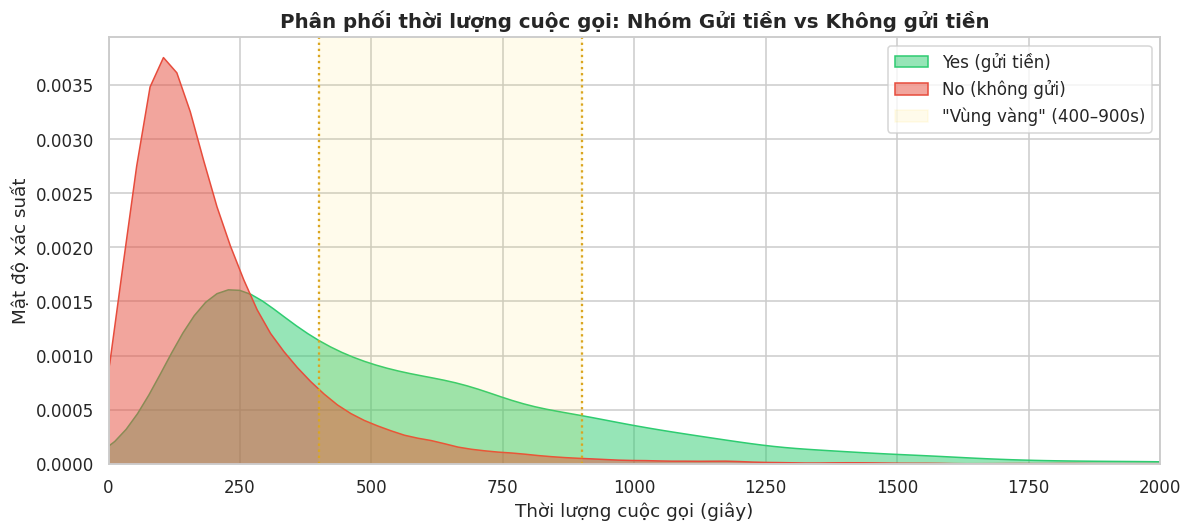

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5))

sns.kdeplot(data=df[df['y']==1], x='duration',
            fill=True, color='#2ecc71', alpha=0.5, label='Yes (gửi tiền)', ax=ax)
sns.kdeplot(data=df[df['y']==0], x='duration',
            fill=True, color='#e74c3c', alpha=0.5, label='No (không gửi)', ax=ax)

ax.axvspan(400, 900, alpha=0.08, color='gold', label='"Vùng vàng" (400–900s)')
ax.axvline(400, color='goldenrod', linestyle=':', linewidth=1.5)
ax.axvline(900, color='goldenrod', linestyle=':', linewidth=1.5)

ax.set_xlim(0, 2000)
ax.set_xlabel('Thời lượng cuộc gọi (giây)', fontsize=12)
ax.set_ylabel('Mật độ xác suất', fontsize=12)
ax.set_title('Phân phối thời lượng cuộc gọi: Nhóm Gửi tiền vs Không gửi tiền',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

med_yes = df[df['y']==1]['duration'].median()
med_no  = df[df['y']==0]['duration'].median()

## Nhận xét

- Nhóm **Yes** có thời lượng gọi dài hơn nhiều: median **426s** so với **164s** của nhóm No (trung bình **537s** so với **221s**).
- Tỉ lệ đồng ý tăng mạnh theo thời lượng: ≤120s: **1.5%** · 120–240s: **7.4%** · 240–400s: **13.9%** · 400–900s: **30.3%** · >900s: **59.2%**.
- ⚠️ **Đây là biến gây target leakage:** `duration` chỉ biết **sau khi cuộc gọi kết thúc** (và cuộc gọi dài thường *là hệ quả* của việc khách quan tâm). Nó rất hữu ích để **đánh giá chất lượng cuộc gọi sau chiến dịch**, nhưng **không dùng được để dự đoán trước cuộc gọi**. Vì vậy các mô hình ở bước sau **mặc định loại bỏ `duration`**.

---
## 3.8 Correlation Heatmap

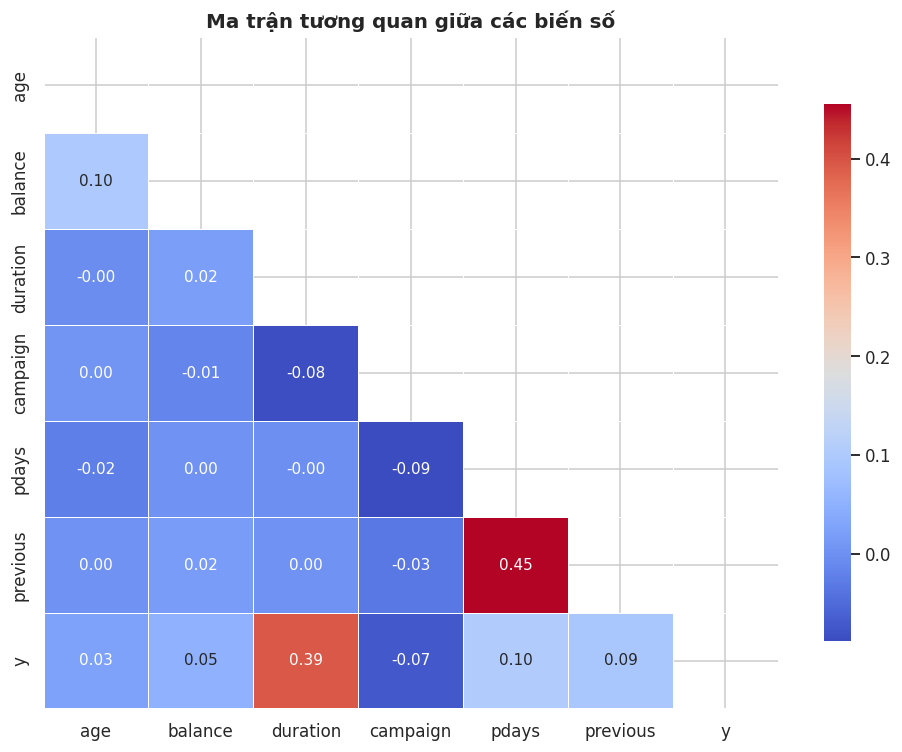

Tương quan với deposit (target):
duration    0.395
pdays       0.104
previous    0.093
campaign   -0.073
balance     0.053
age         0.025

→ duration có tương quan cao nhất (0.395) nhưng là biến gây leakage (chỉ biết sau cuộc gọi).
→ Trong các biến dùng được trước cuộc gọi: pdays (0.104), previous (0.093), balance (0.053) cao nhất.
→ campaign tương quan âm: gọi càng nhiều lần → tỉ lệ thành công càng giảm.


In [ ]:
numeric_cols = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous', 'y']
corr = df[numeric_cols].corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax,
            annot_kws={'size': 10})
ax.set_title('Ma trận tương quan giữa các biến số', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Tương quan với deposit (target):')
print(corr['y'].drop('y').sort_values(key=abs, ascending=False).round(3).to_string())
print('\n→ duration có tương quan cao nhất (0.395) nhưng là biến gây leakage (chỉ biết sau cuộc gọi).')
print('→ Trong các biến dùng được trước cuộc gọi: pdays (0.104), previous (0.093), balance (0.053) cao nhất.')
print('→ campaign tương quan âm: gọi càng nhiều lần → tỉ lệ thành công càng giảm.')

---
## 3.9 Số lần liên hệ (`campaign`) và số dư (`balance`)

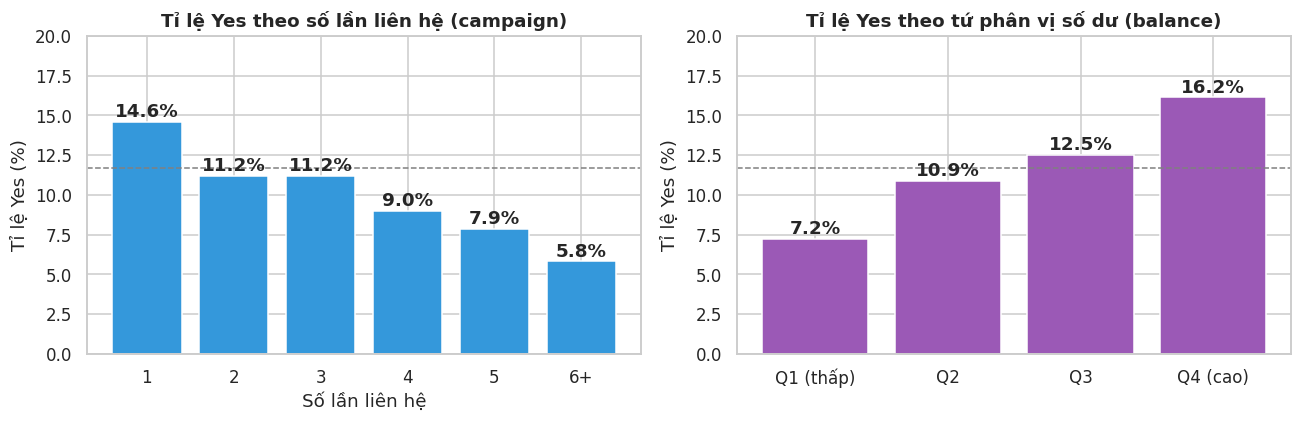

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

camp = df.groupby(df['campaign'].clip(upper=6))['y'].mean() * 100
axes[0].bar([str(i) if i < 6 else '6+' for i in camp.index], camp.values, color='#3498db', edgecolor='white')
for i, v in enumerate(camp.values):
    axes[0].text(i, v + 0.3, f'{v:.1f}%', ha='center', fontweight='bold')
axes[0].axhline(BASE, color='gray', linestyle='--', linewidth=1)
axes[0].set_title('Tỉ lệ Yes theo số lần liên hệ (campaign)', fontweight='bold')
axes[0].set_xlabel('Số lần liên hệ'); axes[0].set_ylabel('Tỉ lệ Yes (%)'); axes[0].set_ylim(0, 20)

bal = df.groupby(pd.qcut(df['balance'], 4), observed=True)['y'].mean() * 100
axes[1].bar(['Q1 (thấp)', 'Q2', 'Q3', 'Q4 (cao)'], bal.values, color='#9b59b6', edgecolor='white')
for i, v in enumerate(bal.values):
    axes[1].text(i, v + 0.3, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].axhline(BASE, color='gray', linestyle='--', linewidth=1)
axes[1].set_title('Tỉ lệ Yes theo tứ phân vị số dư (balance)', fontweight='bold')
axes[1].set_ylabel('Tỉ lệ Yes (%)'); axes[1].set_ylim(0, 20)

plt.tight_layout(); plt.show()



**Nhận xét:** gọi **lần đầu** có tỉ lệ cao nhất (**14.6%**), giảm dần còn **5.8%** khi bị gọi từ 6 lần trở lên → gọi lặp lại nhiều lần kém hiệu quả. Số dư càng cao tỉ lệ càng tăng, từ **7.2%** (25% thấp nhất) lên **16.2%** (25% cao nhất).



## 🎯 Key Business Insights – Marketing Campaign Response Prediction

> Tỉ lệ Yes trung bình toàn tập: **11.7%**. Mọi so sánh dưới đây đều so với mốc này.

## 1. Thời lượng cuộc gọi (`duration`) — mạnh nhưng KHÔNG dùng để dự đoán trước

**Phân tích:** nhóm đồng ý có thời lượng gọi trung bình ~**537s**, gấp ~2.4 lần nhóm từ chối (~**221s**). Tỉ lệ đồng ý tăng từ **1.5%** (≤2 phút) lên **59.2%** (>15 phút).

**Ý nghĩa:** `duration` chỉ biết sau cuộc gọi, nên đây là **chỉ báo chất lượng cuộc gọi**, không phải công cụ chọn khách trước khi gọi. Mô hình dự đoán trước phải loại biến này.

**Hành động:** đào tạo telesales giữ khách qua **2 phút đầu** (≤120s gần như không chốt được), tối ưu script mở đầu; dùng `duration` để đánh giá chất lượng cuộc gọi *sau* chiến dịch.

---

## 2. Thời điểm gọi (`month`)

| Tháng | Số cuộc gọi | Tỉ lệ Yes |
|---|---|---|
| May | 13,764 | **6.7%** (thấp nhất) |
| Mar | 477 | **52.0%** |
| Dec | 214 | 46.7% |
| Sep | 579 | 46.5% |
| Oct | 738 | 43.8% |

**Ý nghĩa:** ngân hàng dồn ~30% cuộc gọi vào tháng 5 — tháng hiệu quả thấp nhất. Các tháng Mar/Sep/Oct/Dec chuyển đổi cao nhưng **mẫu nhỏ**, có thể do gọi chọn lọc.

**Hành động:** giảm cường độ gọi đại trà vào tháng 5; **thử nghiệm A/B** tăng quy mô gọi ở Mar/Sep/Oct/Dec để kiểm chứng tỉ lệ có giữ được khi mở rộng.

---

## 3. Khách từng thành công ở chiến dịch trước (`poutcome = success`)

**Phân tích:** tỉ lệ đồng ý **64.7%** (so với 9.2% ở khách chưa từng liên hệ). Nhóm này nhỏ (**1,511 khách ≈ 3.3%**).

**Hành động:** ưu tiên gọi lại danh sách khách `success`; remarketing trước khi gọi khách mới (cold leads).

---

## 4. Phân khúc khách hàng (`job`, `age`, `education`, `balance`)

- **Student** (28.7%) và **Retired** (22.8%) cao gấp 2–2.5 lần trung bình; **blue-collar** thấp nhất (7.3%).
- Tuổi có dạng chữ U: **≤30** (16.3%) và **>60** (42.3%, nhóm nhỏ) cao hơn nhóm 31–60 (~9.9%).
- Học vấn **tertiary** (15.0%) cao hơn **primary** (8.6%).
- Số dư thuộc 25% cao nhất có tỉ lệ **16.2%**, so với **7.2%** ở 25% thấp nhất.

**Hành động:** gói tiết kiệm cho sinh viên; gói thu nhập ổn định cho người nghỉ hưu; ưu tiên khách số dư cao.

---

## 5. Rào cản tài chính (`housing`, `loan`) và kênh liên lạc

- Có vay thế chấp: **7.7%** vs không vay **16.7%**; có vay cá nhân: **6.7%** vs **12.7%**.
- Kênh `contact = unknown` chỉ đạt **4.1%** (so với cellular 14.9%, telephone 13.4%) — nhóm này chiếm **13,019** khách và **~96% nằm ở tháng 5–6**, nên `contact=unknown` phần lớn là dấu hiệu của giai đoạn đầu chiến dịch (khi tỉ lệ chuyển đổi thấp), chứ không hẳn là bản thân kênh liên lạc.
- Gọi lặp: lần 1 đạt **14.6%**, từ lần 6 trở đi còn **5.8%**.

**Hành động:** giảm ưu tiên telesales cho nhóm dư nợ cao; không gọi lặp quá 3–4 lần; ưu tiên kênh di động.

---

# 💡 Executive Summary

**Chuyển từ "gọi đại trà" sang "tiếp cận có mục tiêu":**
- Ưu tiên: khách từng `success`, student/retired, số dư cao, không có khoản vay.
- Tránh: gọi dồn vào tháng 5 và gọi lặp nhiều lần.
- Tăng chất lượng cuộc gọi: giữ khách qua mốc 2 phút (đánh giá bằng `duration` *sau* cuộc gọi).
- Mô hình dự đoán trước cuộc gọi **không dùng `duration`** để tránh data leakage.
